# Setting up Spark and Neon Postgres

### Initialize Spark Context

In [19]:
from pyspark.sql import SparkSession
import pyspark.sql.functions as F

In [20]:
# 1. Create Spark Session
spark = SparkSession.builder \
    .appName("HubwayBikeETL") \
    .config("spark.jars.packages",
            "org.postgresql:postgresql:42.7.13") \
    .getOrCreate()

## YOUR ETL PIPELINE TASK

### Step 1: Data Preparation

- Load the provided Trips and Stations Data into Spark DataFrame.

## DATASET : BIKE SHARING DATA

Trips: https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/bike-data/201508_trip_data.csv

Stations: https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/bike-data/201508_station_data.csv

Zip_Code_Map: https://raw.githubusercontent.com/scpike/us-state-county-zip/master/geo-data.csv

## Reading Data from CSV

In [21]:
from pyspark import SparkFiles

#Reading Trips Data into Dataframe

url = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/bike-data/201508_trip_data.csv"
spark.sparkContext.addFile(url)

trips_df=trips_df = spark.read.csv(SparkFiles.get("201508_trip_data.csv"), header=True, inferSchema=True)

In [22]:
trips_df.printSchema()

root
 |-- Trip ID: integer (nullable = true)
 |-- Duration: integer (nullable = true)
 |-- Start Date: string (nullable = true)
 |-- Start Station: string (nullable = true)
 |-- Start Terminal: integer (nullable = true)
 |-- End Date: string (nullable = true)
 |-- End Station: string (nullable = true)
 |-- End Terminal: integer (nullable = true)
 |-- Bike #: integer (nullable = true)
 |-- Subscriber Type: string (nullable = true)
 |-- Zip Code: string (nullable = true)



In [23]:
## CORRECTING COLUMN NAME FORMAT SINCE IT WILL BE HARD TO HAND SPACED COLUMN NAMES IN SPARK

import pyspark.sql.functions as F

def correct_headers(df):
  return df.select([F.col(col).alias(col.replace(' ', '_')) for col in df.columns])

## USE THIS FUNCTION TO CORRECT HEADERS AND PROCEED WITH YOUR ETL PIPELINE

In [24]:
trips_df.printSchema()

root
 |-- Trip ID: integer (nullable = true)
 |-- Duration: integer (nullable = true)
 |-- Start Date: string (nullable = true)
 |-- Start Station: string (nullable = true)
 |-- Start Terminal: integer (nullable = true)
 |-- End Date: string (nullable = true)
 |-- End Station: string (nullable = true)
 |-- End Terminal: integer (nullable = true)
 |-- Bike #: integer (nullable = true)
 |-- Subscriber Type: string (nullable = true)
 |-- Zip Code: string (nullable = true)



In [25]:
trips_df.show(20)

+-------+--------+---------------+--------------------+--------------+---------------+--------------------+------------+------+---------------+--------+
|Trip ID|Duration|     Start Date|       Start Station|Start Terminal|       End Date|         End Station|End Terminal|Bike #|Subscriber Type|Zip Code|
+-------+--------+---------------+--------------------+--------------+---------------+--------------------+------------+------+---------------+--------+
| 913460|     765|8/31/2015 23:26|Harry Bridges Pla...|            50|8/31/2015 23:39|San Francisco Cal...|          70|   288|     Subscriber|    2139|
| 913459|    1036|8/31/2015 23:11|San Antonio Shopp...|            31|8/31/2015 23:28|Mountain View Cit...|          27|    35|     Subscriber|   95032|
| 913455|     307|8/31/2015 23:13|      Post at Kearny|            47|8/31/2015 23:18|   2nd at South Park|          64|   468|     Subscriber|   94107|
| 913454|     409|8/31/2015 23:10|  San Jose City Hall|            10|8/31/2015 23

In [26]:
#Reading Station Data into Dataframe

url = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/bike-data/201508_station_data.csv"
spark.sparkContext.addFile(url)

stations_df=correct_headers(spark.read.csv(SparkFiles.get("201508_station_data.csv"), header=True, inferSchema=True))

## USE THE FUNCTION CORRECT HEADERS TO CORRECT STATION HEADERS AND PROCEED WITH YOUR ETL PIPELINE

In [27]:
#Reading ZipCode Data into Dataframe

url = "https://raw.githubusercontent.com/scpike/us-state-county-zip/master/geo-data.csv"
spark.sparkContext.addFile(url)

Zip_Code_Map=correct_headers(spark.read.csv(SparkFiles.get("geo-data.csv"), header=True, inferSchema=True))

## USE THE FUNCTION CORRECT HEADERS TO CORRECT STATION HEADERS AND PROCEED WITH YOUR ETL PIPELINE

### Step 2: Data Transformation

- Join the Trips DataFrame with the Stations DataFrame to add Starting Landmark and Ending Landmark columns. (You will require same station to be joined to trips table twice with different joining conditions)
- Use the Zip Code Mapping dataset to add a “State” column to the Trips DataFrame, based on the available Zip Code field.
- Extract the Month_Year from the Start Date.
- Select Relevant Columns Required leave the rest

In [28]:
import pyspark.sql.functions as F

start_stations = stations_df.select(
    F.col("station_id").alias("start_station_id"),
    F.col("landmark").alias("Starting_Landmark")
)

end_stations = stations_df.select(
    F.col("station_id").alias("end_station_id"),
    F.col("landmark").alias("Ending_Landmark")
)

zip_clean = Zip_Code_Map.select(
    F.col("zipcode").cast("string").alias("map_zip"),
    F.col("state_abbr").alias("State")
).dropDuplicates(["map_zip"])

transformed_df = trips_df \
    .join(start_stations, F.col("Start Terminal") == start_stations["start_station_id"], "left") \
    .join(end_stations, F.col("End Terminal") == end_stations["end_station_id"], "left") \
    .join(zip_clean, F.col("Zip Code").cast("string") == zip_clean["map_zip"], "left") \
    .withColumn("State", F.coalesce(F.col("State"), F.lit("Unknown"))) \
    .withColumn("Month_Year", F.date_format(F.to_timestamp(F.col("Start Date"), "M/d/yyyy H:m"), "yyyy-MM")) \
    .select(
        F.col("Trip ID").alias("Trip_ID"),
        F.col("Duration"),
        F.col("Starting_Landmark"),
        F.col("Ending_Landmark"),
        F.col("State"),
        F.col("Subscriber Type").alias("Subscriber_Type"),
        F.col("Month_Year")
    )

transformed_df.printSchema()
transformed_df.show(10)

root
 |-- Trip_ID: integer (nullable = true)
 |-- Duration: integer (nullable = true)
 |-- Starting_Landmark: string (nullable = true)
 |-- Ending_Landmark: string (nullable = true)
 |-- State: string (nullable = false)
 |-- Subscriber_Type: string (nullable = true)
 |-- Month_Year: string (nullable = true)

+-------+--------+-----------------+---------------+-------+---------------+----------+
|Trip_ID|Duration|Starting_Landmark|Ending_Landmark|  State|Subscriber_Type|Month_Year|
+-------+--------+-----------------+---------------+-------+---------------+----------+
| 913460|     765|    San Francisco|  San Francisco|Unknown|     Subscriber|   2015-08|
| 913459|    1036|    Mountain View|  Mountain View|     CA|     Subscriber|   2015-08|
| 913455|     307|    San Francisco|  San Francisco|     CA|     Subscriber|   2015-08|
| 913454|     409|         San Jose|       San Jose|     CA|     Subscriber|   2015-08|
| 913453|     789|    San Francisco|  San Francisco|Unknown|       Custome

### Step 3: Data Aggregation

- Group the DataFrame by Starting Landmark, Ending Landmark, State, Subscriber Type, and Month_Year.
- Calculate the following measures:
  - Number_of_Trips (count distinct Trip_ID)
  - Duration_Total_Minutes (sum of Duration) / 60

In [29]:
aggregated_df = transformed_df.groupBy(
    "Starting_Landmark",
    "Ending_Landmark",
    "State",
    "Subscriber_Type",
    "Month_Year"
).agg(
    F.countDistinct("Trip_ID").alias("Number_of_Trips"),
    (F.sum("Duration") / 60).alias("Duration_Total_Minutes")
)

aggregated_df.printSchema()
aggregated_df.show(20)

root
 |-- Starting_Landmark: string (nullable = true)
 |-- Ending_Landmark: string (nullable = true)
 |-- State: string (nullable = false)
 |-- Subscriber_Type: string (nullable = true)
 |-- Month_Year: string (nullable = true)
 |-- Number_of_Trips: long (nullable = false)
 |-- Duration_Total_Minutes: double (nullable = true)

+-----------------+---------------+-----+---------------+----------+---------------+----------------------+
|Starting_Landmark|Ending_Landmark|State|Subscriber_Type|Month_Year|Number_of_Trips|Duration_Total_Minutes|
+-----------------+---------------+-----+---------------+----------+---------------+----------------------+
|    Mountain View|  Mountain View|   MN|       Customer|   2015-08|             10|                100.85|
|         San Jose|       San Jose|   CA|       Customer|   2014-09|            148|    32897.316666666666|
|        Palo Alto|      Palo Alto|   CA|       Customer|   2014-09|             57|     4888.833333333333|
|    San Francisco|  Sa

### Step 4: Save the Data in Neon Postgre (It's guide is available in the instruction document)



In [31]:
#After replacing above properties then run this cell as it is
jdbc_url = f"jdbc:postgresql://{PGHOST}/{PGDATABASE}?sslmode={PGSSLMODE}"

properties = {
    "user": PGUSER,
    "password": PGPASSWORD,
    "driver": "org.postgresql.Driver"
}

In [32]:
#for neon db.dump
aggregated_df.write.jdbc(
    url=jdbc_url,
    table="Trips_transformed_alishba",
    mode="overwrite",
    properties=properties
)

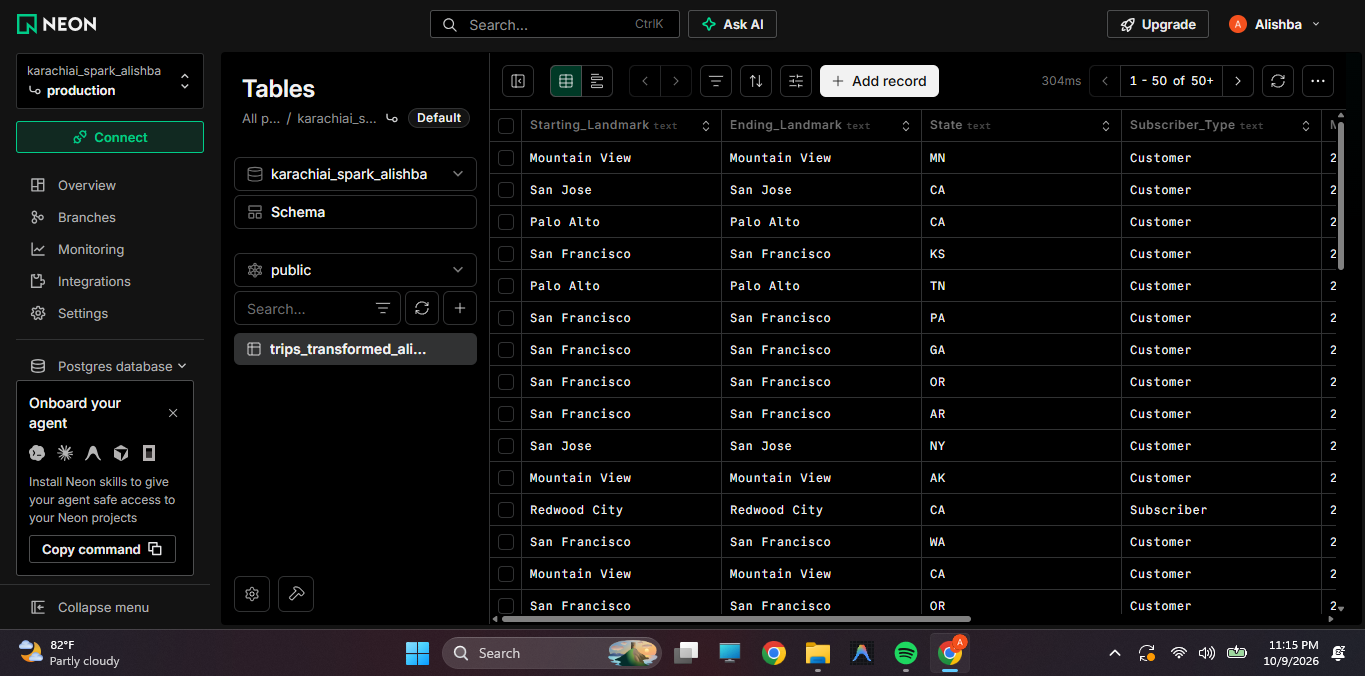

#### Upload your Spark Transformation Notebook / Script + Your neon postgres table data screenshot